## Szeged térségi geotermikus erőmű – bemeneti adatmodul

**Készítette:** Baranyi Bartal (EUL1SB)

### A modul célja
Ebben a notebookban készítjük elő a geotermikus forrásparamétereket, a meteorológiai idősort és a fogyasztói adatokat a csapat többi tagja számára az ORC-modellhez és a dinamikus éves szimulációhoz.

### Vizsgálati koncepció (Hibrid erőmű)
Bár a projekt fókuszában a villamosenergia-termelés áll, a gazdasági megtérülés érdekében a modellt egy másodlagos hőhasznosítási körrel is kiegészítettük. A cél egy 10 MW nettó villamos kapacitású erőmű, amely az ORC-ből kilépő maradékhőt közvetlenül értékesíti a szegedi BYD gyár festőüzemének technológiai fűtésére.

### Fő peremfeltételek
* **Helyszín és forrás:** Szeged térsége, új kútrendszerrel. A 2500 m-es célmélységben az SZTFH OGRe adatbázisa alapján 125 °C-os talphőmérséklettel számolunk.
* **Hőmérsékletek:** A primer ORC belépő 115 °C, a kilépő pedig 65 °C[cite: 4]. A festőüzemi visszatérő ágat 35 °C-ra vettük fel.
* **Kúthozam:** A valós szegedi adatokra támaszkodva egy optimalizált, 40 kg/s-os kútonkénti tömegárammal számolunk.
* **Meteorológia:** 8760 órás PVGIS TMY (2014–2023) UTC-indexált adatsor a dinamikus szimulációhoz.
* **Fogyasztás:** A BYD becsült 283,4 GWh éves energiaigénye, amit egy állandó, illetve egy változó (nappal/éjszaka) profil formájában adunk át.

In [45]:
import math
import pandas as pd

# --- Alapadatok és peremfeltételek ---
# Földtani és kút paraméterek (OGRe térkép alapján ~2500m -> 125°C)
T_res = 125.0
T_in = 115.0       # ORC primer belépő [°C]
T_out = 65.0       # ORC primer kilépő [°C]
T_paint = 35.0     # Festőüzem fűtési visszatérő [°C]

m_dot_well = 40.0  # Névleges termelőkút tömegáram [kg/s]
cp = 4.18          # Víz fajhője [kJ/kgK]

# Erőművi célkitűzés és hatásfok
P_net_target = 10000.0  # Célzott nettó villamos teljesítmény [kW] (15 MW)
eta_net = 0.09          # 9% nettó hatásfok (segédüzemi fogyasztással csökkentve)

# --- Teljesítmények kútonként ---
# Primer hőteljesítmény (ORC)
Q_orc_well = m_dot_well * cp * (T_in - T_out)

# Nettó villamos teljesítmény kútonként
P_net_well = Q_orc_well * eta_net

# Szükséges kútszám
N_wells = math.ceil(P_net_target / P_net_well)

# Szekunder hőteljesítmény (BYD festőüzem melegvíz)
Q_paint_well = m_dot_well * cp * (T_out - T_paint)

print(f"Kútonkénti kinyerhető primer hő (ORC): {Q_orc_well/1000:.2f} MW")
print(f"Kútonkénti nettó villamos teljesítmény: {P_net_well/1000:.2f} MW")
print(f"Szükséges termelőkutak száma a 10 MW eléréséhez: {N_wells} db")
print(f"Teljes maradékhő kapacitás: {(N_wells * Q_paint_well)/1000:.2f} MW\n")

# --- Forrásoldali forgatókönyvek (Az elvárt több eset vizsgálatához) ---
scenarios = pd.DataFrame({
    "Eset": ["Alacsony hozam", "Alapeset", "Magas hozam"],
    "m_dot_kút_[kg/s]": [25.0, 40.0, 50.0]
})

scenarios["Kútszám"] = N_wells
scenarios["Össz_tömegáram_[kg/s]"] = scenarios["m_dot_kút_[kg/s]"] * scenarios["Kútszám"]

# Összesített hőteljesítmények [MW]
scenarios["Q_ORC_total_[MW]"] = (scenarios["Össz_tömegáram_[kg/s]"] * cp * (T_in - T_out)) / 1000
scenarios["Q_Hő_total_[MW]"] = (scenarios["Össz_tömegáram_[kg/s]"] * cp * (T_out - T_paint)) / 1000

print("--- Forgatókönyvek összehasonlítása ---")
print(scenarios.to_string(index=False))

Kútonkénti kinyerhető primer hő (ORC): 8.36 MW
Kútonkénti nettó villamos teljesítmény: 0.75 MW
Szükséges termelőkutak száma a 10 MW eléréséhez: 14 db
Teljes maradékhő kapacitás: 70.22 MW

--- Forgatókönyvek összehasonlítása ---
          Eset  m_dot_kút_[kg/s]  Kútszám  Össz_tömegáram_[kg/s]  Q_ORC_total_[MW]  Q_Hő_total_[MW]
Alacsony hozam              25.0       14                  350.0             73.15           43.890
      Alapeset              40.0       14                  560.0            117.04           70.224
   Magas hozam              50.0       14                  700.0            146.30           87.780


In [42]:
import numpy as np
from pathlib import Path
from pvlib.iotools import get_pvgis_tmy

# --- Helyszín és szimulációs paraméterek ---
lat = 46.25       # Szeged térsége szélesség [°]
lon = 20.15       # Szeged térsége hosszúság [°]
sim_year = 2025   # Vizsgálati év

# Kimeneti mappa előkészítése
out_dir = Path("output")
out_dir.mkdir(exist_ok=True)

# --- 1. PVGIS TMY meteorológiai adatsor letöltése (2014-2023) ---
print(f"TMY adatok letöltése a PVGIS adatbázisból ({lat}°, {lon}°)...")
raw_tmy, pvgis_meta = get_pvgis_tmy(
    latitude=lat,
    longitude=lon,
    outputformat="json",
    map_variables=False,
    coerce_year=None,
    startyear=2014,
    endyear=2023,
    url="https://re.jrc.ec.europa.eu/api/v5_3/",
    timeout=60
)

# --- 2. Adatvalidáció és minőségellenőrzés ---
if len(raw_tmy) != 8760:
    raise ValueError(f"Hibás idősor hossz! 8760 óra helyett {len(raw_tmy)} érkezett.")

req_cols = ["T2m", "RH", "WS10m", "SP"]
if not all(col in raw_tmy.columns for col in req_cols):
    raise ValueError(f"Hiányzó oszlopok a PVGIS válaszban: {req_cols}")

# Típuskonverzió float-ra a matematikai műveletekhez
tmy_data = raw_tmy[req_cols].astype(float)

# Fizikai korlátok és teljesség ellenőrzése
if tmy_data.isnull().values.any() or not np.isfinite(tmy_data.values).all():
    raise ValueError("Kritikus hiba: Hiányzó (NaN) vagy végtelen érték az adatokban.")

if not tmy_data["RH"].between(0, 100).all():
    raise ValueError("Fizikai képtelenség: a relatív páratartalom (RH) nincs 0-100% között.")

if (tmy_data["WS10m"] < 0).any() or (tmy_data["SP"] <= 0).any():
    raise ValueError("Fizikai képtelenség: negatív szélsebesség vagy légnyomás.")

# Eredeti PVGIS adatsor mentése biztonsági mentésként
raw_tmy.to_csv(out_dir / "pvgis_tmy_original.csv", index_label="source_time")

# --- 3. Változók átnevezése fizikai standardok szerint ---
weather = tmy_data.rename(columns={
    "T2m": "T_air",       # Külső léghőmérséklet [°C]
    "RH": "rh",           # Relatív páratartalom [%]
    "WS10m": "v_wind",    # Szélsebesség 10m-en [m/s]
    "SP": "p_air",        # Légnyomás [Pa]
})

# Eredeti PVGIS időbélyeg megőrzése referenciaként
weather.insert(0, "tmy_source_utc", raw_tmy.index.astype(str))

# --- 4. Szimulációs UTC időindex beállítása ---
weather.index = pd.date_range(
    start=f"{sim_year}-01-01",
    periods=8760,
    freq="h",
    tz="UTC",
    name="time_utc"
)

print("\nMeteorológiai adatmodul sikeresen betöltve.")
display(weather.head())

TMY adatok letöltése a PVGIS adatbázisból (46.25°, 20.15°)...

Meteorológiai adatmodul sikeresen betöltve.


,tmy_source_utc,T_air,rh,v_wind,p_air
time_utc,,,,,
2025-01-01 00:00:00+00:00,2019-01-01 00:00:00+00:00,-1.10,89.14,2.24,102030.0
2025-01-01 01:00:00+00:00,2019-01-01 01:00:00+00:00,-1.29,90.47,2.15,102070.0
2025-01-01 02:00:00+00:00,2019-01-01 02:00:00+00:00,-1.48,91.80,2.06,102050.0
2025-01-01 03:00:00+00:00,2019-01-01 03:00:00+00:00,-1.67,93.13,1.97,102020.0
2025-01-01 04:00:00+00:00,2019-01-01 04:00:00+00:00,-1.87,94.46,1.88,101990.0


In [ ]:
import json
import numpy as np
import pandas as pd

# A BYD becsült éves villamosenergia-igénye
annual_demand_MWh = 283400.0

# 1. Órás bemeneti idősor kibővítése a forrásadatokkal
hourly_inputs = weather.copy()

# Állandó referencia fogyasztás [kW] kiosztása a 8760 órára
hourly_inputs["P_demand_ref_[kW]"] = (annual_demand_MWh * 1000) / len(hourly_inputs)

# Alapeseti forrásadatok kiválasztása a 'scenarios' táblából
base_case = scenarios.loc[scenarios["Eset"] == "Alapeset"].iloc[0]

# Állandó forrásparaméterek rögzítése az idősorhoz
hourly_inputs["T_in_[°C]"] = T_in
hourly_inputs["T_out_[°C]"] = T_out
hourly_inputs["T_paint_return_[°C]"] = T_paint
hourly_inputs["m_dot_total_[kg/s]"] = base_case["Össz_tömegáram_[kg/s]"]

# Validáció: az órás referenciafogyasztások összege kiadja-e az évest
annual_demand_check_MWh = hourly_inputs["P_demand_ref_[kW]"].sum() / 1000
assert np.isclose(annual_demand_check_MWh, annual_demand_MWh)

# 2. Eredmények exportálása
hourly_inputs.to_csv(out_dir / "hourly_inputs.csv")
scenarios.to_csv(out_dir / "scenarios.csv", index=False)

# 3. Metaadatok és modellkorlátok rögzítése a projekt dokumentációjához
metadata = {
    "parameters": {
        "T_res_C": T_res,
        "T_in_C": T_in,
        "T_out_C": T_out,
        "T_paint_C": T_paint,
        "m_dot_well_kg_s": m_dot_well,
        "P_net_target_kW": P_net_target,
        "eta_net": eta_net,
        "N_wells": N_wells
    },
    "pvgis_meta": {
        "months_selected": pvgis_meta["months_selected"],
        "inputs": pvgis_meta["inputs"]
    },
    "limitations": [
        "Új, hipotetikus geotermikus kútrendszer (az OGRe becslésére alapozva).",
        "A 115 °C-os felszíni belépő hőmérséklet és a kúthozam tervezési feltevés, nem fúrással igazolt adat.",
        "A BYD villamos- és hőigénye becsült konstans referencia, nem a gyárból származó tényleges mérési adatsor.",
        "A TMY szintetikus UTC időtengelye klímaátlagot mutat, nem konkrét jövőbeli időjárás-előrejelzést.",
        "A segédüzemi szivattyúk nyomásigényét és pontos karakterisztikáját egyelőre egy fix 25%-os parazita fogyasztási rátával (bruttó -> nettó hatásfok) egyszerűsítettük."
    ]
}

# JSON kiírása (magyar ékezetes karakterek helyes kezelésével)
with open(out_dir / "input_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2, default=str)

# 4. Összefoglaló a notebookba

summary = pd.Series({
    "Szimulált órák száma [h]": len(hourly_inputs),
    "Éves referencia áramigény (BYD) [GWh]": annual_demand_MWh / 1000,
    "Átlagos külső hőmérséklet [°C]": round(weather["T_air"].mean(), 2),
    "Min/Max hőmérséklet [°C]": str(t_min) + " / " + str(t_max),
    "Alapeset - Össz tömegáram [kg/s]": base_case["Össz_tömegáram_[kg/s]"],
    "Alapeset - Kinyerhető ORC hőteljesítmény [MW]": base_case["Q_ORC_total_[MW]"],
    "Alapeset - Hőteljesítmény [MW]": base_case["Q_Hő_total_[MW]"]
})

print("--- Adatmodul Kimeneti Összefoglaló ---")
display(summary)

--- Adatmodul Kimeneti Összefoglaló ---


Szimulált órák száma [h]                                 8760
Éves referencia áramigény (BYD) [GWh]                   283.4
Átlagos külső hőmérséklet [°C]                          13.53
Min/Max hőmérséklet [°C]                         -9.76 / 36.2
Alapeset - Össz tömegáram [kg/s]                        560.0
Alapeset - Kinyerhető ORC hőteljesítmény [MW]          117.04
Alapeset - Hőteljesítmény [MW]                         70.224
dtype: object

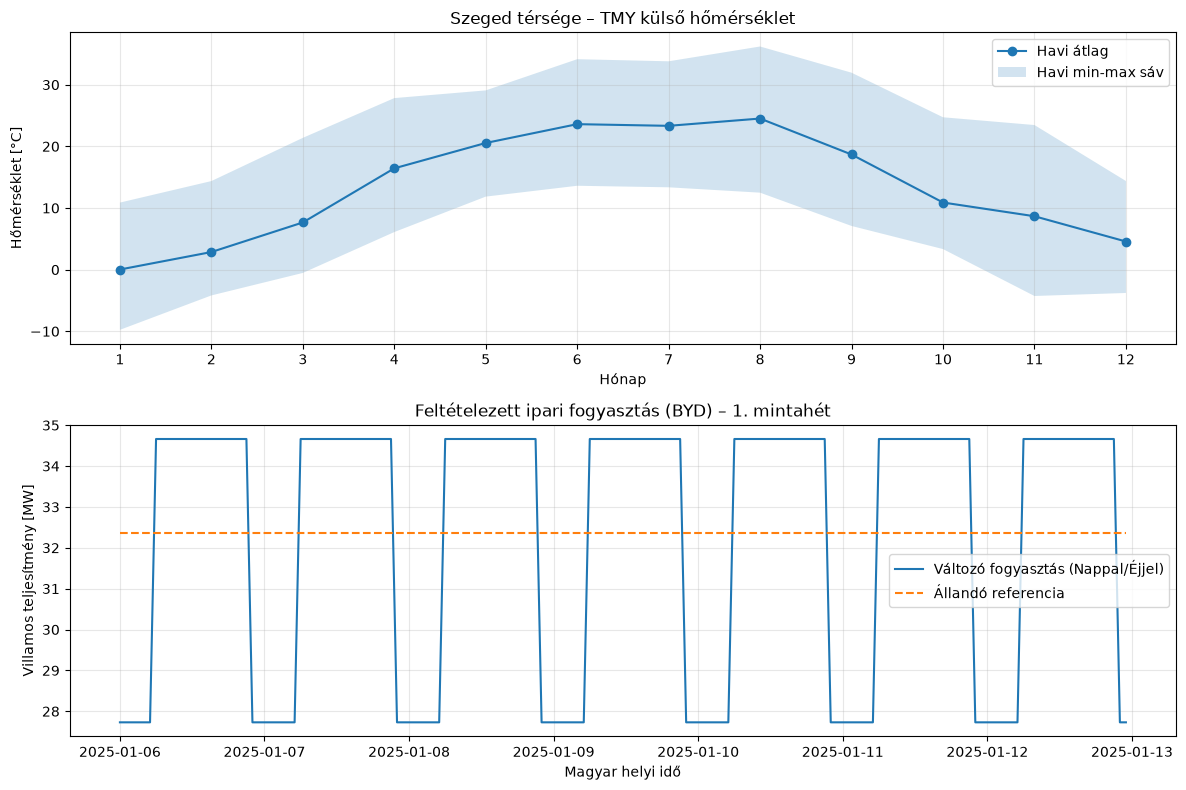

In [36]:
import matplotlib.pyplot as plt

# --- 5. Változó fogyasztási profil (Nappal/Éjszaka) ---
local_index = hourly_inputs.index.tz_convert("Europe/Budapest")
day_shift = (local_index.hour >= 6) & (local_index.hour < 22)
weights = np.where(day_shift, 1.00, 0.80).astype(float)

# Igény szétosztása a súlyok alapján (éves energiaösszeg változatlan marad)
hourly_inputs["P_demand_var_[kW]"] = weights * (annual_demand_MWh * 1000) / (weights.sum() * 1.0)

# CSV újraexportálása a teljes adattáblával
hourly_inputs.to_csv(out_dir / "hourly_inputs.csv")

# --- 6. Vizualizáció a prezentációhoz ---
# Havi átlaghőmérsékletek kinyerése a plot-hoz
monthly_temp = hourly_inputs["T_air"].resample("MS").agg(["mean", "min", "max"])

# Egy januári mintahét kiválasztása a fogyasztás ábrázolásához
week_mask = (local_index >= pd.Timestamp("2025-01-06", tz="Europe/Budapest")) & \
            (local_index < pd.Timestamp("2025-01-13", tz="Europe/Budapest"))
week = hourly_inputs.loc[week_mask].copy()
week.index = week.index.tz_convert("Europe/Budapest")

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Felső grafikon: Meteorológia
axes[0].plot(monthly_temp.index.month, monthly_temp["mean"], marker="o", label="Havi átlag")
axes[0].fill_between(monthly_temp.index.month, monthly_temp["min"], monthly_temp["max"], alpha=0.2, label="Havi min-max sáv")
axes[0].set(title="Szeged térsége – TMY külső hőmérséklet", xlabel="Hónap", ylabel="Hőmérséklet [°C]", xticks=range(1, 13))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Alsó grafikon: Villamosenergia-igény
axes[1].plot(week.index, week["P_demand_var_[kW]"] / 1000, label="Változó fogyasztás (Nappal/Éjjel)")
axes[1].plot(week.index, week["P_demand_ref_[kW]"] / 1000, linestyle="--", label="Állandó referencia")
axes[1].set(title="Feltételezett ipari fogyasztás (BYD) – 1. mintahét", xlabel="Magyar helyi idő", ylabel="Villamos teljesítmény [MW]")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(out_dir / "input_profiles_check.png", dpi=200, bbox_inches="tight")
plt.show()

## Rendszerhatárok és a modell korlátai

A fenti számítások alapján a 10 MW nettó villamos teljesítmény eléréséhez 14 db termelőkútra (és ugyanennyi visszasajtolóra) van szükségünk. A feladatkiírás elvárásainak megfelelően bevezettünk három különböző forrásoldali forgatókönyvet (25, 40 és 50 kg/s kúthozam) a későbbi optimalizáláshoz és az érzékenységvizsgálathoz.

**Fontosabb modellkorlátok és feltevések:**
* **Elméleti kútadatok:** A 125 °C-os talphőmérséklet és a 40 kg/s-os hozam reális tervezési feltevések, de nem próbafúrással igazolt tények. A kutak nyomásviszonyait és a visszasajtolás pontos szivattyúzási energiaigényét nem modellezzük felületi szinten; ezt egy előzetes, 9%-os nettó (parazita fogyasztással már csökkentett) hatásfok-becsléssel hidaltuk át.
* **Meteorológia és Fogyasztás:** A PVGIS TMY adatbázis egy sokéves klímaátlagot mutat, nem konkrét időjárás-előrejelzés. A BYD energiaigénye egy referenciabecslés, amelynél gyári leállásokkal és karbantartási ünnepnapokkal nem számoltunk.
* **Hálózat és értékesítés:** Feltételezzük, hogy az erőmű folyamatos zsinórüzemben tud termelni, és a gyár (vagy a hálózat) minden megtermelt áramot és hőt azonnal át tud venni. Személyre szabott szigetüzemet nem modellezünk.